<img src = "https://drive.google.com/uc?export=view&id=1lrzkRlmABf8ZwwCzsSvo0b2lW_IhZXkv" alt = "Encabezado MLDS" width = "100%">  </img>


# **Preparación de los datos**
---

Este notebook es una plantilla que le puede servir como guía para el tercer entregable del proyecto aplicado.

## **0. Integrantes del equipo de trabajo**
---

Por favor incluya los nombres completos y número de identificación de los integrantes del equipo de trabajo:

1. ---**Hernando Jose Vela 17593509**---
2. ---**Oscar Javier Restrepo 79660922**
3. ---**Juan David Vasquez Pinzon 1002459526**---

## **1. Limpieza de los Datos**
---

La elección de las técnicas de preprocesamiento puede diferir en cada conjunto de datos. Recuerde que es posible aplicar, según sea necesario (no necesariamente todas), las técnicas generales que se han explorado en el curso. La elección dependerá del tipo de datos con el que esté trabajando.

A lo largo de esta entrega, busque responder las siguientes preguntas:

- ¿Cuáles fueron los criterios utilizados para identificar y tratar valores atípicos, datos faltantes o cualquier otra anomalía en el conjunto de datos durante el proceso de limpieza?
- ¿Cómo se justificaría la necesidad de cada paso de preprocesamiento en términos de mejora de la calidad de los datos y preparación para el análisis subsiguiente?

A continuación encontrará los puntos a tratar a medida que va realizando la preparación de los datos. En cada punto defina el estado en que se encontraba el dataset, ademas de explicar y justificar las acciones y decisiones que se tomaron.

### **1.1. Valores faltantes**
---
Al encontrarnos con valores faltantes en el conjunto de datos, es crucial preguntarse:
* ¿Cómo afectan estos valores a la integridad y representatividad de la información?
* ¿Cómo se identificaron los valores faltantes en el conjunto de datos?
* ¿Cuáles fueron los criterios para decidir si rellenar con valores estimados o eliminar los valores faltantes? En caso que aplique, ¿qué método de relleno se utilizó y por qué se consideró apropiado?
* ¿Se realizó un análisis de la distribución de los valores faltantes en relación con las variables clave? Por ejemplo, si hay valores faltantes en una variable crítica, ¿cómo podría afectar la interpretación de los resultados?

---**INGRESE SU RESPUESTA**---

### 1.1. Valores faltantes

**Estado inicial de los datos**

El conjunto de datos *Heart Failure Prediction* contiene 918 registros y 12 variables, de las cuales 11 son predictoras y una corresponde a la variable objetivo `HeartDisease`.

Durante la fase de entendimiento de los datos se verificó que ninguna de las variables presenta valores nulos explícitos (`NaN`). Sin embargo, se identificaron valores numéricos que podrían representar información faltante o mediciones inválidas:

- **`Cholesterol`:** 172 registros presentan un valor igual a cero (18,74 % del conjunto).
- **`RestingBP`:** 1 registro presenta un valor igual a cero (0,11 % del conjunto).

Estos valores requieren tratamiento porque una concentración de colesterol sérico o una presión arterial en reposo igual a cero no representan mediciones fisiológicas válidas para los pacientes registrados.

**Criterios para el tratamiento**

Se propone considerar los valores cero de `Cholesterol` y `RestingBP` como valores faltantes encubiertos, reemplazándolos inicialmente por `NaN`.

No se propone eliminar automáticamente los registros afectados, especialmente porque los valores cero de colesterol representan una proporción considerable del conjunto. Su eliminación reduciría la cantidad de observaciones disponibles y podría introducir sesgos si la ausencia de información está relacionada con las características de los pacientes.

Como estrategia inicial se propone utilizar la **imputación mediante la mediana**, por ser una medida robusta frente a valores extremos. Sin embargo, esta decisión deberá validarse durante la evaluación de los modelos.

Para evitar filtración de información (*data leakage*), los valores de imputación se calcularán exclusivamente a partir del conjunto de entrenamiento y posteriormente se aplicarán a los conjuntos de validación o prueba.

**Análisis de la distribución de los valores faltantes**

Se examinará si los registros con valores cero presentan diferencias en la distribución de la variable objetivo `HeartDisease`. Este análisis permitirá determinar si la ausencia de información podría estar asociada con la presencia de enfermedad cardíaca.

También se evaluará la conveniencia de incorporar indicadores binarios que identifiquen los registros cuyos valores fueron originalmente faltantes.

**Decisión preliminar**

Se conservarán los 918 registros y se marcarán como faltantes los valores cero identificados en `Cholesterol` y `RestingBP`. La imputación se realizará posteriormente, utilizando exclusivamente la información del conjunto de entrenamiento.

In [ ]:
# ---INGRESE SU CÓDIGO---
import io
import zipfile
import requests
import numpy as np
import pandas as pd
from IPython.display import display

# Cargar el conjunto de datos desde Kaggle.
url = "https://www.kaggle.com/api/v1/datasets/download/fedesoriano/heart-failure-prediction"
response = requests.get(url, timeout=60)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    df_original = pd.read_csv(z.open("heart.csv"))

df = df_original.copy()

# Identificar valores faltantes explícitos y encubiertos.
resumen = pd.DataFrame({
    "Nulos explícitos": df.isna().sum(),
    "Ceros observados": (df == 0).sum()
})

display(resumen.loc[["Cholesterol", "RestingBP"]])

# Analizar los ceros en relación con la variable objetivo.
for variable in ["Cholesterol", "RestingBP"]:
    tabla = pd.crosstab(df[variable] == 0, df["HeartDisease"])
    tabla.index = ["Valor distinto de cero", "Valor igual a cero"]
    print(f"\nDistribución de HeartDisease según {variable}:")
    display(tabla)

# Marcar como faltantes los valores cero de las dos variables.
df[["Cholesterol", "RestingBP"]] = df[["Cholesterol", "RestingBP"]].replace(0, np.nan)

print("\nValores faltantes después del tratamiento:")
display(df.isna().sum().to_frame("Cantidad"))

,Nulos explícitos,Ceros observados
Cholesterol,0,172
RestingBP,0,1



Distribución de HeartDisease según Cholesterol:


HeartDisease,0,1
Valor distinto de cero,390,356
Valor igual a cero,20,152



Distribución de HeartDisease según RestingBP:


HeartDisease,0,1
Valor distinto de cero,410,507
Valor igual a cero,0,1



Valores faltantes después del tratamiento:


,Cantidad
Age,0
Sex,0
ChestPainType,0
RestingBP,1
Cholesterol,172
FastingBS,0
RestingECG,0
MaxHR,0
ExerciseAngina,0
Oldpeak,0


### Conservación de los datos originales y conjunto de trabajo

Para garantizar la trazabilidad y reproducibilidad del proceso de preparación, se utilizarán dos estructuras de datos independientes:

- **`df_original`:** contiene una copia íntegra del conjunto de datos descargado desde Kaggle. Se conservará sin modificaciones durante toda la fase 3 y servirá como referencia para verificar los valores originales, contrastar resultados y documentar las transformaciones realizadas.
- **`df`:** corresponde a una copia de trabajo sobre la cual se aplicarán las operaciones de limpieza, tratamiento de valores faltantes, verificación de inconsistencias y selección de características.

Esta separación permite evaluar el efecto de cada transformación sin alterar la información de origen.

Las operaciones que requieran estimar parámetros a partir de los datos, como la imputación mediante la mediana o el escalado de variables, se ajustarán exclusivamente con el conjunto de entrenamiento para evitar la filtración de información (*data leakage*).

De esta manera, se mantiene una distinción entre los datos originales, las transformaciones deterministas de limpieza y los procedimientos estadísticos que posteriormente se utilizarán para preparar los datos destinados al modelado.

In [ ]:
# Calcular la proporción de enfermedad cardíaca según la disponibilidad del colesterol.
resumen_colesterol = pd.crosstab(
    df_original["Cholesterol"].eq(0),
    df_original["HeartDisease"],
    normalize="index"
) * 100

resumen_colesterol.index = ["Colesterol registrado", "Colesterol igual a cero"]
resumen_colesterol.columns = ["Sin enfermedad (%)", "Con enfermedad (%)"]

display(resumen_colesterol.round(2))

# Crear un indicador de ausencia de colesterol.
df["Cholesterol_missing"] = df_original["Cholesterol"].eq(0).astype(int)

print("Distribución del indicador:")
display(df["Cholesterol_missing"].value_counts().sort_index())

,Sin enfermedad (%),Con enfermedad (%)
Colesterol registrado,52.28,47.72
Colesterol igual a cero,11.63,88.37


Distribución del indicador:


,count
Cholesterol_missing,
0,746
1,172


In [ ]:
# Calcular la proporción de enfermedad cardíaca según la disponibilidad del colesterol.
resumen_colesterol = pd.crosstab(
    df_original["Cholesterol"].eq(0),
    df_original["HeartDisease"],
    normalize="index"
) * 100

resumen_colesterol.index = ["Colesterol registrado", "Colesterol igual a cero"]
resumen_colesterol.columns = ["Sin enfermedad (%)", "Con enfermedad (%)"]

display(resumen_colesterol.round(2))

# Crear un indicador de ausencia de colesterol.
df["Cholesterol_missing"] = df_original["Cholesterol"].eq(0).astype(int)

print("Distribución del indicador:")
display(df["Cholesterol_missing"].value_counts().sort_index())

**Resultados del análisis de valores faltantes**

La revisión confirmó que el conjunto de datos no contiene valores nulos explícitos. Sin embargo, se identificaron 172 registros con `Cholesterol = 0` (18,74 %) y un registro con `RestingBP = 0` (0,11 %), considerados valores faltantes encubiertos por no corresponder a mediciones fisiológicas válidas.

El análisis de la relación entre estos valores y la variable objetivo `HeartDisease` reveló una diferencia importante: entre los pacientes con colesterol registrado, el 47,72 % presenta enfermedad cardíaca, mientras que entre aquellos con colesterol igual a cero esta proporción asciende al 88,37 %.

Este resultado evidencia una asociación entre la ausencia de información de colesterol y la variable objetivo. Aunque no permite establecer la causa de dicha asociación, indica que la eliminación de los registros afectados podría modificar considerablemente la composición del conjunto de datos.

**Decisiones de preparación**

1. Conservar los 918 registros originales.
2. Reemplazar los valores cero de `Cholesterol` y `RestingBP` por `NaN`.
3. Incorporar la variable indicadora `Cholesterol_missing`, que permitirá identificar los registros cuyo valor original de colesterol estaba ausente.
4. Utilizar inicialmente imputación mediante la mediana para ambas variables, calculada exclusivamente sobre los datos de entrenamiento.
5. Evaluar posteriormente si la incorporación del indicador mejora el desempeño predictivo, comparando modelos con y sin esta característica.

Estas decisiones permiten conservar la mayor cantidad posible de información y establecer un procedimiento reproducible de preparación, evitando la filtración de información durante el ajuste de las transformaciones.

In [4]:
# Verificar que el conjunto original permanezca intacto.
assert df_original.shape == (918, 12)
assert df_original["Cholesterol"].eq(0).sum() == 172
assert df_original["RestingBP"].eq(0).sum() == 1

# Verificar las transformaciones realizadas sobre la copia de trabajo.
assert df["Cholesterol"].isna().sum() == 172
assert df["RestingBP"].isna().sum() == 1
assert df["Cholesterol_missing"].sum() == 172

print("Verificación correcta: datos originales conservados y transformaciones aplicadas.")

Verificación correcta: datos originales conservados y transformaciones aplicadas.


### **1.2. Valores duplicados**
----
Ante la presencia de valores duplicados, es esencial reflexionar sobre su impacto en los resultados.

* ¿Cómo se identificaron y manejaron los valores duplicados en el conjunto de datos?
* ¿Hubo alguna consideración especial al tratar duplicados en función de ciertas variables?
* ¿Pueden estos duplicados sesgar el análisis, y en qué medida?
* ¿Se justifica la eliminación de duplicados para mantener la coherencia y singularidad de los datos?
* ¿Cómo se aseguró de que la eliminación de duplicados no afectara negativamente la representación del conjunto de datos?

La identificación y eliminación de duplicados busca asegurar que cada registro aporte información única y valiosa.

---**INGRESE SU RESPUESTA**---

**Identificación y tratamiento de valores duplicados**

Durante la fase de entendimiento de los datos se verificó la presencia de registros duplicados en el conjunto *Heart Failure Prediction*, compuesto por 918 observaciones.

La identificación se realizó mediante el método `duplicated()` de Pandas, que permite detectar filas cuyos valores coinciden completamente con los de registros anteriores.

En esta fase se verificará nuevamente la existencia de duplicados, considerando dos conjuntos:

- **`df_original`:** conjunto de datos original, conservado sin modificaciones.
- **`df`:** conjunto de trabajo, que incorpora las transformaciones realizadas durante la preparación de los datos.

**Criterios de evaluación**

Se consideran duplicados exactos aquellos registros que presentan los mismos valores en todas sus columnas.

Sin embargo, debe distinguirse entre registros idénticos y pacientes duplicados. Dado que el conjunto no contiene un identificador único de paciente, dos registros con características clínicas iguales no necesariamente corresponden a la misma persona.

También se comprobará si existen observaciones con características predictoras idénticas, pero con etiquetas diferentes de `HeartDisease`, ya que esta situación podría representar información contradictoria o pacientes distintos con características coincidentes.

**Estrategia de tratamiento**

No se eliminarán registros automáticamente. La decisión dependerá de los resultados de las verificaciones y de la posibilidad de justificar que dos observaciones representan realmente una duplicación.

La eliminación injustificada podría reducir la representatividad del conjunto y modificar la distribución de las clases.

Finalmente, se verificará que las transformaciones realizadas durante la preparación no hayan generado duplicados adicionales.

In [5]:
# ---INGRESE SU CÓDIGO---
# Verificar duplicados exactos en los conjuntos original y de trabajo.
duplicados_original = df_original.duplicated().sum()
duplicados_trabajo = df.duplicated().sum()

# Comparar registros utilizando únicamente las variables predictoras.
columnas_predictoras = df_original.columns.drop("HeartDisease")
duplicados_X = df_original.duplicated(subset=columnas_predictoras).sum()

# Identificar características idénticas asociadas a etiquetas diferentes.
etiquetas_por_grupo = df_original.groupby(
    list(columnas_predictoras), dropna=False
)["HeartDisease"].nunique()

grupos_contradictorios = (etiquetas_por_grupo > 1).sum()

# Resumen de resultados.
resumen_duplicados = pd.DataFrame({
    "Verificación": [
        "Duplicados exactos en df_original",
        "Duplicados exactos en df",
        "Duplicados en variables predictoras",
        "Grupos con etiquetas contradictorias"
    ],
    "Cantidad": [
        duplicados_original,
        duplicados_trabajo,
        duplicados_X,
        grupos_contradictorios
    ]
})

display(resumen_duplicados)

,Verificación,Cantidad
0,Duplicados exactos en df_original,0
1,Duplicados exactos en df,0
2,Duplicados en variables predictoras,0
3,Grupos con etiquetas contradictorias,0


In [6]:
# Confirmar que no se han perdido registros durante la preparación.
assert len(df) == len(df_original), "Se modificó la cantidad de registros."

# Confirmar que el conjunto original conserva sus columnas.
assert df_original.shape == (918, 12), "El conjunto original fue modificado."

print(f"Registros originales: {len(df_original)}")
print(f"Registros conservados: {len(df)}")
print("Verificación de conservación de registros completada.")

Registros originales: 918
Registros conservados: 918
Verificación de conservación de registros completada.


**Resultados y decisiones**

La revisión de registros duplicados confirmó que el conjunto *Heart Failure Prediction* no presenta duplicaciones que requieran tratamiento. Se realizaron cuatro verificaciones:

- **Duplicados exactos en `df_original`:** no se identificaron registros completamente idénticos.
- **Duplicados exactos en `df`:** no se encontraron duplicados después de las transformaciones realizadas en la sección 1.1.
- **Duplicados en las variables predictoras:** no se identificaron observaciones con combinaciones idénticas de características clínicas y demográficas.
- **Grupos con etiquetas contradictorias:** no se encontraron registros con características predictoras idénticas y diferentes valores de `HeartDisease`.

Adicionalmente, se comprobó que tanto `df_original` como `df` conservan los **918 registros iniciales**, lo que confirma que no se han eliminado observaciones durante las operaciones de preparación realizadas hasta el momento.

**Decisión de tratamiento**

Dado que no se identificaron duplicados exactos ni coincidencias entre las variables predictoras, **no se requiere aplicar procedimientos de eliminación de registros duplicados**.

Esta decisión permite conservar la totalidad de las observaciones disponibles, evitando modificaciones innecesarias que podrían afectar la representatividad del conjunto de datos.

Asimismo, se mantiene la distinción entre `df_original`, que conserva los datos originales sin modificaciones, y `df`, sobre el cual se realizan las transformaciones de preparación.

En consecuencia, se considera completada la revisión de duplicados y se continuará con los **918 registros originales** en las siguientes etapas del proceso.

### **1.3. Valores atípicos**
---
Al abordar valores atípicos, es relevante cuestionarse sobre la naturaleza de estos puntos extremos.
* ¿Son errores de medición o representan información válida pero excepcional?
* ¿Qué criterios o técnicas se utilizaron para identificar los valores atípicos?
* ¿Se aplicaron métodos estadísticos o visuales para detectar los valores atípicos?
* ¿Cuál fue la decisión final sobre cómo tratar los valores atípicos y por qué?

La elección entre eliminar o transformar estos valores debe basarse en su influencia en la distribución y la interpretación de los resultados, asegurando que el análisis refleje de manera precisa la realidad del conjunto de datos.

**Identificación y tratamiento de valores atípicos**

Durante la fase de entendimiento de los datos se realizó un análisis de valores atípicos sobre las cinco variables numéricas del conjunto *Heart Failure Prediction*: `Age`, `RestingBP`, `Cholesterol`, `MaxHR` y `Oldpeak`.

La identificación se realizó mediante diagramas de caja (*boxplots*) y el criterio del rango intercuartílico (IQR), que considera atípicos los valores ubicados fuera del intervalo:

$$
[Q_1 - 1.5 \cdot IQR,\ Q_3 + 1.5 \cdot IQR]
$$

donde $IQR = Q_3 - Q_1$.

**Resultados de la fase 2**

El análisis exploratorio identificó:

- **`Age`:** no se encontraron valores atípicos mediante IQR.
- **`RestingBP`:** se identificaron 28 valores atípicos, incluido un valor igual a cero.
- **`Cholesterol`:** se identificaron 183 valores atípicos, de los cuales 172 corresponden a valores iguales a cero.
- **`MaxHR`:** se encontraron 2 valores atípicos.
- **`Oldpeak`:** se identificaron 16 valores atípicos.

**Criterios de tratamiento**

Se distinguirán dos situaciones:

1. **Valores inválidos:** observaciones incompatibles con una medición fisiológica válida, como los valores cero de colesterol y presión arterial identificados previamente. Estos valores ya fueron convertidos a `NaN` en la sección 1.1.
2. **Valores extremos potencialmente válidos:** observaciones que se encuentran fuera de los límites estadísticos del IQR, pero que podrían corresponder a condiciones clínicas reales.

No se eliminarán automáticamente los valores extremos, dado que podrían contener información relevante para distinguir pacientes con y sin enfermedad cardíaca.

Se realizará una nueva evaluación sobre el conjunto de trabajo `df`, después de identificar los valores faltantes encubiertos. Esto permitirá distinguir los valores extremos restantes de aquellos que ya fueron tratados como faltantes.

La decisión final de conservar, transformar o limitar valores atípicos se fundamentará en los resultados del análisis y en su posible impacto sobre el modelado.

---**INGRESE SU RESPUESTA**---

In [7]:
# ---INGRESE SU CÓDIGO---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Variables numéricas identificadas en la fase 2.
numeric_columns = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]

def analizar_atipicos(datos, columnas):
    resultados = []

    for col in columnas:
        valores = datos[col].dropna()
        q1, q3 = valores.quantile([0.25, 0.75])
        iqr = q3 - q1
        li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        atipicos = ((valores < li) | (valores > ls)).sum()

        resultados.append({
            "Variable": col,
            "Q1": q1,
            "Q3": q3,
            "Límite inferior": li,
            "Límite superior": ls,
            "Atípicos": int(atipicos),
            "Atípicos (%)": 100 * atipicos / len(valores)
        })

    return pd.DataFrame(resultados)

# Comparar los resultados antes y después del tratamiento de valores cero.
atipicos_original = analizar_atipicos(df_original, numeric_columns)
atipicos_trabajo = analizar_atipicos(df, numeric_columns)

comparacion = pd.DataFrame({
    "Variable": numeric_columns,
    "Atípicos originales": atipicos_original["Atípicos"],
    "Atípicos actuales": atipicos_trabajo["Atípicos"],
    "Límite inferior actual": atipicos_trabajo["Límite inferior"],
    "Límite superior actual": atipicos_trabajo["Límite superior"]
})

display(comparacion.round(2))

,Variable,Atípicos originales,Atípicos actuales,Límite inferior actual,Límite superior actual
0,Age,0,0,27.50,79.50
1,RestingBP,28,27,90.00,170.00
2,Cholesterol,183,23,105.62,376.62
3,MaxHR,2,2,66.00,210.00
4,Oldpeak,16,16,-2.25,3.75


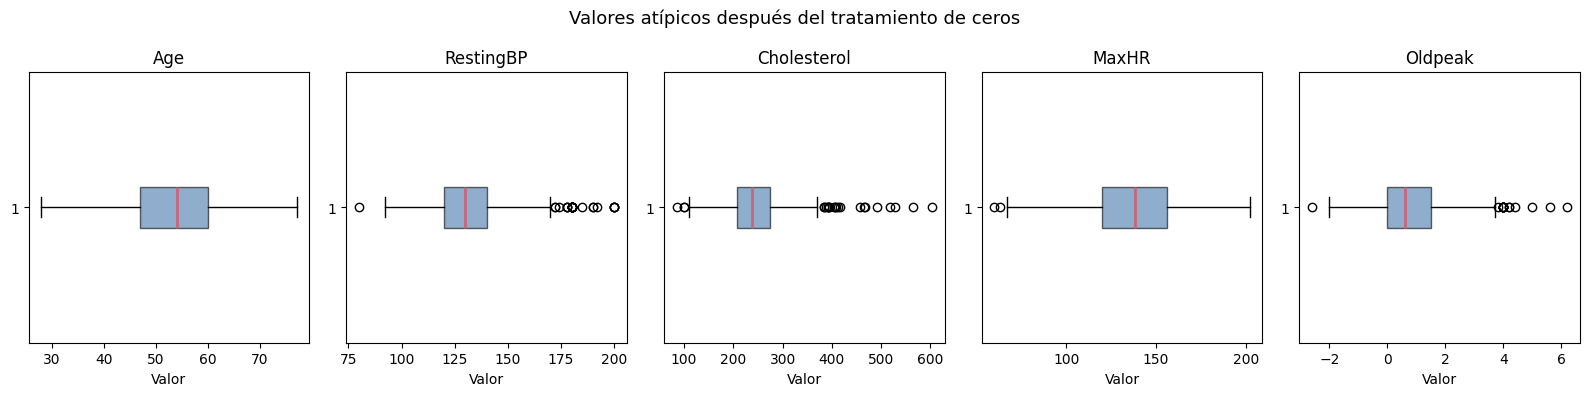

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))

for ax, col in zip(axes, numeric_columns):
    ax.boxplot(df[col].dropna(), vert=False, patch_artist=True,
               boxprops={"facecolor": "#4477AA", "alpha": 0.6},
               medianprops={"color": "#CC6677", "linewidth": 2})
    ax.set_title(col)
    ax.set_xlabel("Valor")

fig.suptitle("Valores atípicos después del tratamiento de ceros", fontsize=13)
plt.tight_layout()
plt.show()

In [9]:
# Verificar que el tratamiento de atípicos no eliminó registros.
assert len(df) == 918
assert df_original.shape == (918, 12)

# Verificar que los valores faltantes identificados se mantienen.
assert df["Cholesterol"].isna().sum() == 172
assert df["RestingBP"].isna().sum() == 1

# Verificar que el indicador de colesterol faltante se conserva.
assert df["Cholesterol_missing"].sum() == 172

print("Verificación correcta: valores atípicos conservados y 918 registros disponibles.")

Verificación correcta: valores atípicos conservados y 918 registros disponibles.


**Resultados y decisiones**

La reevaluación de valores atípicos mediante el criterio del rango intercuartílico (IQR) permitió comparar el conjunto original `df_original` con el conjunto de trabajo `df`, después de identificar los valores faltantes encubiertos en `Cholesterol` y `RestingBP`.

Los resultados fueron los siguientes:

- **`Age`:** no se identificaron valores atípicos, ni antes ni después del tratamiento.
- **`RestingBP`:** los valores atípicos disminuyeron de 28 a 27, debido a que el registro con presión arterial igual a cero fue identificado como faltante.
- **`Cholesterol`:** los valores atípicos pasaron de 183 a 23. Esta reducción se explica por la conversión de 172 valores cero en `NaN` y por el cambio de los límites estadísticos del IQR al recalcular los cuartiles sobre los valores disponibles.
- **`MaxHR`:** se mantuvieron 2 valores atípicos.
- **`Oldpeak`:** se mantuvieron 16 valores atípicos.

Los diagramas de caja permitieron visualizar la distribución de las variables y confirmar la presencia de observaciones extremas en cuatro de las cinco variables numéricas.

**Criterios de tratamiento**

Se estableció una distinción entre valores fisiológicamente inválidos y valores estadísticamente atípicos que podrían representar observaciones clínicas reales.

Los valores cero de `Cholesterol` y `RestingBP` ya fueron tratados como datos faltantes encubiertos en la sección 1.1, conservando los registros correspondientes para su posterior imputación.

En cuanto a los valores extremos restantes, no se dispone de evidencia suficiente para considerarlos errores de medición o registro. Su eliminación podría excluir pacientes con características clínicas relevantes para la identificación de enfermedad cardíaca.

**Decisión final**

Se decidió **conservar los valores atípicos restantes sin aplicar eliminación, truncamiento ni sustitución automática**.

Esta decisión permite preservar la variabilidad clínica del conjunto y evitar la pérdida de información potencialmente relevante para el aprendizaje automático.

Las transformaciones estadísticas que puedan resultar necesarias durante el modelado, como el escalado de variables, se ajustarán exclusivamente con los datos de entrenamiento para evitar filtración de información.

En consecuencia, el conjunto de trabajo conserva los **918 registros originales**, manteniendo como valores faltantes únicamente los 172 registros de `Cholesterol` y el registro de `RestingBP` identificados previamente.

### **1.4. Datos Inconsistentes**
---
Frente a inconsistencias en los datos, es importante analizar cómo estas discrepancias podrían afectar la comparabilidad y comprensión de la información.

* ¿Cómo se identificaron las inconsistencias en los datos?
* ¿Las inconsistencias son lo suficientemente significativas como para justificar una estandarización?
* ¿Cómo se pueden homogeneizar unidades y formatos para garantizar coherencia en el análisis?
* ¿Qué estrategias se implementaron para abordar las inconsistencias y asegurar la coherencia?
* ¿Se establecieron reglas de validación específicas para garantizar la consistencia?

**Identificación y tratamiento de datos inconsistentes**

Durante la fase de entendimiento de los datos se verificaron los tipos de almacenamiento, las categorías observadas y los rangos de las variables del conjunto *Heart Failure Prediction*.

El análisis inicial no identificó categorías inesperadas ni problemas de codificación. Sin embargo, durante la preparación se requiere comprobar que las transformaciones aplicadas mantengan la coherencia de los registros.

**Criterios de validación**

Se evaluarán los siguientes aspectos:

1. **Consistencia de las variables categóricas:** verificar que los valores observados correspondan a las categorías documentadas para cada variable.
2. **Consistencia de los tipos de datos:** comprobar que las variables numéricas puedan interpretarse como números y que las variables categóricas mantengan representaciones compatibles con su significado.
3. **Consistencia de rangos:** identificar valores incompatibles con restricciones básicas, diferenciándolos de observaciones extremas que podrían ser clínicamente válidas.
4. **Consistencia de la variable objetivo:** verificar que `HeartDisease` contenga exclusivamente las etiquetas 0 y 1, sin valores faltantes.
5. **Consistencia de las transformaciones:** comprobar que los valores cero de `Cholesterol` y `RestingBP` permanezcan identificados como faltantes y que el indicador `Cholesterol_missing` corresponda a los valores originales.

**Estrategia de tratamiento**

No se modificarán automáticamente las observaciones que superen las validaciones establecidas.

Si se identifican inconsistencias adicionales, se documentará su naturaleza y se determinará si requieren corrección, transformación o exclusión.

Se conservará `df_original` como referencia intacta y se aplicarán las modificaciones justificadas exclusivamente sobre `df`.

---**INGRESE SU RESPUESTA**---

In [10]:
# ---INGRESE SU CÓDIGO---
# Categorías esperadas según la documentación del conjunto de datos.
categorias_esperadas = {
    "Sex": {"M", "F"},
    "ChestPainType": {"TA", "ATA", "NAP", "ASY"},
    "FastingBS": {0, 1},
    "RestingECG": {"Normal", "ST", "LVH"},
    "ExerciseAngina": {"Y", "N"},
    "ST_Slope": {"Up", "Flat", "Down"},
    "HeartDisease": {0, 1}
}

# Identificar valores no contemplados y valores faltantes.
resultados_categorias = []

for col, permitidos in categorias_esperadas.items():
    inesperados = df.loc[df[col].notna() & ~df[col].isin(permitidos), col]

    resultados_categorias.append({
        "Variable": col,
        "Categorías esperadas": len(permitidos),
        "Categorías observadas": df[col].nunique(),
        "Valores inesperados": len(inesperados),
        "Valores faltantes": df[col].isna().sum()
    })

display(pd.DataFrame(resultados_categorias))

,Variable,Categorías esperadas,Categorías observadas,Valores inesperados,Valores faltantes
0,Sex,2,2,0,0
1,ChestPainType,4,4,0,0
2,FastingBS,2,2,0,0
3,RestingECG,3,3,0,0
4,ExerciseAngina,2,2,0,0
5,ST_Slope,3,3,0,0
6,HeartDisease,2,2,0,0


In [11]:
# Verificar que las variables numéricas contienen números válidos o NaN.
numeric_columns = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]

resultados_tipos = pd.DataFrame({
    "Variable": numeric_columns,
    "Tipo": [str(df[col].dtype) for col in numeric_columns],
    "No numéricos": [
        pd.to_numeric(df[col], errors="coerce").isna().sum() - df[col].isna().sum()
        for col in numeric_columns
    ],
    "Valores infinitos": [
        np.isinf(pd.to_numeric(df[col], errors="coerce")).sum()
        for col in numeric_columns
    ]
})

display(resultados_tipos)

# Validar restricciones básicas de coherencia.
validaciones = {
    "Age <= 0": (df["Age"] <= 0).sum(),
    "RestingBP <= 0": (df["RestingBP"] <= 0).sum(),
    "Cholesterol <= 0": (df["Cholesterol"] <= 0).sum(),
    "MaxHR <= 0": (df["MaxHR"] <= 0).sum(),
    "HeartDisease fuera de {0, 1}": (~df["HeartDisease"].isin([0, 1])).sum()
}

display(pd.DataFrame(validaciones.items(), columns=["Validación", "Inconsistencias"]))

,Variable,Tipo,No numéricos,Valores infinitos
0,Age,int64,0,0
1,RestingBP,float64,0,0
2,Cholesterol,float64,0,0
3,MaxHR,int64,0,0
4,Oldpeak,float64,0,0


,Validación,Inconsistencias
0,Age <= 0,0
1,RestingBP <= 0,0
2,Cholesterol <= 0,0
3,MaxHR <= 0,0
4,"HeartDisease fuera de {0, 1}",0


In [12]:
# Comprobar correspondencia entre datos originales y transformados.
ceros_colesterol = df_original["Cholesterol"].eq(0)
ceros_presion = df_original["RestingBP"].eq(0)

verificaciones = {
    "Indicador de colesterol correcto":
        df["Cholesterol_missing"].eq(ceros_colesterol.astype(int)).all(),

    "Valores faltantes de colesterol correctos":
        df["Cholesterol"].isna().eq(ceros_colesterol).all(),

    "Valores faltantes de presión correctos":
        df["RestingBP"].isna().eq(ceros_presion).all(),

    "Variable objetivo sin modificaciones":
        df["HeartDisease"].equals(df_original["HeartDisease"]),

    "Cantidad de registros conservada":
        len(df) == len(df_original)
}

display(pd.DataFrame(
    verificaciones.items(),
    columns=["Verificación", "Resultado"]
))

assert all(verificaciones.values()), "Se encontraron inconsistencias en las transformaciones."

print("Verificación de transformaciones completada correctamente.")

,Verificación,Resultado
0,Indicador de colesterol correcto,True
1,Valores faltantes de colesterol correctos,True
2,Valores faltantes de presión correctos,True
3,Variable objetivo sin modificaciones,True
4,Cantidad de registros conservada,True


Verificación de transformaciones completada correctamente.


**Resultados y decisiones**

La evaluación de consistencia del conjunto *Heart Failure Prediction* permitió verificar la coherencia de las variables categóricas, los tipos de datos, las restricciones numéricas básicas y las transformaciones realizadas durante la preparación.

**Consistencia de las variables categóricas**

Se verificaron las seis variables predictoras categóricas (`Sex`, `ChestPainType`, `FastingBS`, `RestingECG`, `ExerciseAngina` y `ST_Slope`), además de la variable objetivo `HeartDisease`.

En todos los casos, las categorías observadas coincidieron con las documentadas para el conjunto de datos. No se identificaron valores inesperados ni valores faltantes.

**Consistencia de los tipos de datos y rangos**

Las cinco variables numéricas (`Age`, `RestingBP`, `Cholesterol`, `MaxHR` y `Oldpeak`) presentan tipos de almacenamiento compatibles con su naturaleza y no contienen valores no numéricos ni infinitos.

Las verificaciones de restricciones básicas tampoco identificaron valores incompatibles con las condiciones establecidas: edades no positivas, presiones arteriales no positivas, concentraciones de colesterol no positivas o frecuencias cardíacas máximas no positivas.

Los valores cero de `Cholesterol` y `RestingBP`, identificados previamente como faltantes encubiertos, permanecen representados mediante `NaN` en el conjunto de trabajo.

El cambio de tipo de `int64` a `float64` en estas dos variables es consecuencia de la incorporación de valores faltantes y no constituye una inconsistencia.

**Consistencia de las transformaciones**

Se comprobaron cinco condiciones:

1. El indicador `Cholesterol_missing` identifica correctamente los registros cuyo valor original de colesterol era cero.
2. Los valores faltantes de `Cholesterol` corresponden exactamente a los registros identificados en el conjunto original.
3. Los valores faltantes de `RestingBP` corresponden al registro originalmente identificado.
4. La variable objetivo `HeartDisease` permanece sin modificaciones.
5. La cantidad de registros se conserva después de las transformaciones.

Todas las verificaciones fueron satisfactorias.

**Decisión final**

No se identificaron inconsistencias adicionales que requieran correcciones, eliminación de registros o estandarización de categorías y unidades.

Se decidió conservar las representaciones originales de las variables, manteniendo únicamente las transformaciones justificadas en las secciones anteriores.

El conjunto de trabajo `df` conserva los **918 registros originales**, junto con el indicador adicional `Cholesterol_missing` y los valores faltantes identificados en `Cholesterol` y `RestingBP`.

Las operaciones posteriores de codificación categórica, imputación y escalado se realizarán durante la preparación para el modelado, ajustando los parámetros estadísticos exclusivamente sobre los datos de entrenamiento para evitar filtración de información.

En consecuencia, se considera completada la revisión de consistencia de los datos.

### **1.5. Datos corruptos**
---
En la detección de datos corruptos, pregunte si hay posibles errores de entrada o problemas de transferencia que podrían haber afectado la integridad de los datos.
* ¿Cómo se determinó la presencia de datos corruptos en el conjunto de datos?
* ¿Qué medidas se tomaron para corregir o eliminar los datos corruptos?
* ¿Hubo casos en los que la corrupción de datos no pudo ser manejada y cómo se justificó esa decisión?

---**INGRESE SU RESPUESTA**---

**Identificación y tratamiento de datos corruptos**

La corrupción de datos puede producirse por errores durante la descarga, transferencia, almacenamiento o interpretación de un archivo. Estos problemas pueden manifestarse mediante archivos incompletos, errores de codificación, estructuras incorrectas, registros truncados o modificaciones involuntarias.

En el proyecto *Heart Failure Prediction*, los datos se obtienen desde Kaggle mediante un archivo comprimido que contiene `heart.csv`.

Durante las fases anteriores se verificó que el conjunto contiene 918 registros y 12 variables, y que los datos presentan categorías y tipos compatibles con su documentación.

Sin embargo, estas comprobaciones no garantizan por sí solas que el archivo haya sido descargado e interpretado correctamente.

**Criterios de validación**

Se realizarán las siguientes verificaciones:

1. **Integridad del archivo:** comprobar que el archivo original existe, puede leerse y contiene información.
2. **Integridad estructural:** verificar que el número de registros, los nombres de las columnas y los tipos de datos sean compatibles con la estructura esperada.
3. **Integridad del contenido:** comprobar que no existan registros completamente vacíos, nombres de columnas duplicados o valores incompatibles con las validaciones establecidas.
4. **Integridad de las transformaciones:** confirmar que la preparación realizada sobre `df` no haya modificado accidentalmente el conjunto `df_original`.

**Estrategia de tratamiento**

Si se identifican problemas de lectura o estructura, se deberá revisar la fuente y repetir la adquisición del archivo antes de continuar.

No se corregirán automáticamente registros cuya información original no pueda recuperarse de manera confiable.

Se utilizará una huella digital SHA-256 para identificar el contenido del archivo analizado y facilitar su trazabilidad. Esta huella permite comparar archivos, aunque no demuestra por sí sola que el contenido sea correcto o auténtico.

In [13]:
# ---INGRESE SU CÓDIGO---
import io
import hashlib
import zipfile
import pandas as pd
from IPython.display import display

# Verificar integridad del ZIP descargado.
with zipfile.ZipFile(io.BytesIO(response.content)) as archivo_zip:
    archivo_danado = archivo_zip.testzip()
    archivos_disponibles = archivo_zip.namelist()
    contenido_csv = archivo_zip.read("heart.csv")

# Calcular la huella digital del archivo CSV.
sha256 = hashlib.sha256(contenido_csv).hexdigest()

# Leer nuevamente el CSV para verificar su interpretación.
df_verificacion = pd.read_csv(io.BytesIO(contenido_csv))

resumen_integridad = pd.DataFrame({
    "Verificación": [
        "Archivo ZIP sin errores CRC detectados",
        "Archivo heart.csv presente",
        "Archivo CSV no vacío",
        "Número de registros esperado",
        "Número de columnas esperado",
        "Contenido coincide con df_original"
    ],
    "Resultado": [
        archivo_danado is None,
        "heart.csv" in archivos_disponibles,
        len(contenido_csv) > 0,
        len(df_verificacion) == 918,
        df_verificacion.shape[1] == 12,
        df_verificacion.equals(df_original)
    ]
})

display(resumen_integridad)
print(f"SHA-256 del archivo heart.csv:\n{sha256}")

,Verificación,Resultado
0,Archivo ZIP sin errores CRC detectados,True
1,Archivo heart.csv presente,True
2,Archivo CSV no vacío,True
3,Número de registros esperado,True
4,Número de columnas esperado,True
5,Contenido coincide con df_original,True


SHA-256 del archivo heart.csv:
948420b084d8a3a0ca42b8419fce9aee175879e43f8aedf712377899a67aa49b


In [14]:
# Columnas esperadas según la documentación del conjunto.
columnas_esperadas = [
    "Age", "Sex", "ChestPainType", "RestingBP", "Cholesterol",
    "FastingBS", "RestingECG", "MaxHR", "ExerciseAngina",
    "Oldpeak", "ST_Slope", "HeartDisease"
]

# Evaluar la estructura y el contenido del conjunto original.
validaciones_estructura = {
    "Columnas esperadas y en el orden correcto":
        df_original.columns.tolist() == columnas_esperadas,

    "Nombres de columnas únicos":
        df_original.columns.is_unique,

    "Sin registros completamente vacíos":
        not df_original.isna().all(axis=1).any(),

    "Sin columnas completamente vacías":
        not df_original.isna().all(axis=0).any(),

    "Variable objetivo válida":
        df_original["HeartDisease"].isin([0, 1]).all(),

    "Sin diferencias respecto al archivo descargado":
        df_original.equals(df_verificacion)
}

display(pd.DataFrame(
    validaciones_estructura.items(),
    columns=["Verificación", "Resultado"]
))

,Verificación,Resultado
0,Columnas esperadas y en el orden correcto,True
1,Nombres de columnas únicos,True
2,Sin registros completamente vacíos,True
3,Sin columnas completamente vacías,True
4,Variable objetivo válida,True
5,Sin diferencias respecto al archivo descargado,True


In [15]:
# Reconstruir las transformaciones documentadas desde los datos originales.
df_reconstruido = df_original.copy(deep=True)

df_reconstruido[["Cholesterol", "RestingBP"]] = (
    df_reconstruido[["Cholesterol", "RestingBP"]].replace(0, np.nan)
)

df_reconstruido["Cholesterol_missing"] = (
    df_original["Cholesterol"].eq(0).astype(int)
)

# Verificar que la copia de trabajo coincide con las transformaciones esperadas.
assert df.equals(df_reconstruido), (
    "El conjunto de trabajo contiene diferencias no documentadas."
)

assert df_original.equals(df_verificacion), (
    "El conjunto original no coincide con el archivo descargado."
)

print("Verificación correcta: integridad y transformaciones documentadas.")

Verificación correcta: integridad y transformaciones documentadas.


**Resultados y decisiones**

La evaluación de integridad del conjunto *Heart Failure Prediction* permitió verificar que el archivo original fue descargado e interpretado correctamente y que las transformaciones realizadas durante la preparación son reproducibles.

**Integridad del archivo**

Se comprobó que el archivo comprimido descargado desde Kaggle supera la verificación CRC, contiene `heart.csv` y permite recuperar su contenido sin errores detectados.

La lectura del archivo confirmó las dimensiones esperadas de **918 registros y 12 variables**, así como su correspondencia exacta con el conjunto `df_original`.

Adicionalmente, se calculó una huella digital SHA-256 del archivo CSV, que permite identificar el contenido utilizado y facilitar futuras comprobaciones de integridad.

**Integridad estructural y del contenido**

Las verificaciones confirmaron que:

- Los nombres y el orden de las columnas corresponden a la estructura documentada.
- No existen nombres de columnas duplicados.
- No se identificaron registros completamente vacíos.
- No se identificaron columnas completamente vacías.
- La variable objetivo `HeartDisease` contiene exclusivamente valores válidos.
- El contenido de `df_original` coincide con el archivo CSV descargado.

**Integridad de las transformaciones**

Se reconstruyó el conjunto de trabajo a partir de `df_original`, aplicando nuevamente las transformaciones documentadas:

1. Conversión de los valores cero de `Cholesterol` y `RestingBP` en valores faltantes (`NaN`).
2. Incorporación de la variable indicadora `Cholesterol_missing`.

La comparación confirmó que el conjunto reconstruido coincide exactamente con `df`. Asimismo, se verificó que `df_original` permanece sin modificaciones.

**Decisión final**

No se detectaron errores de lectura, transferencia, estructura o modificaciones no documentadas mediante las pruebas realizadas. Por tanto, **no se requiere corregir, reconstruir ni eliminar registros por corrupción detectada**.

Es importante señalar que estas verificaciones no garantizan la exactitud clínica de todas las mediciones originales. Sin embargo, proporcionan evidencia de que el archivo conserva su integridad estructural y de que las transformaciones realizadas son consistentes y reproducibles.

En consecuencia, se conservan los **918 registros originales** y se considera completada la revisión de datos corruptos.

### **1.6. Selección de datos**
---
En la selección de datos, reflexione sobre las variables que son realmente relevantes para sus objetivos de análisis.
* ¿Qué criterios se utilizaron para seleccionar los datos relevantes para el análisis?
* ¿Se aplicaron técnicas de muestreo o filtrado para reducir el tamaño del conjunto de datos?
* ¿Cómo se justificó la inclusión o exclusión de ciertas variables en la selección de datos?

---**INGRESE SU RESPUESTA**---

**Criterios de selección de datos**

El objetivo del proyecto es desarrollar modelos de aprendizaje automático que permitan clasificar la presencia o ausencia de enfermedad cardíaca a partir de características clínicas y demográficas de los pacientes.

Durante las etapas anteriores se verificó que el conjunto *Heart Failure Prediction* contiene 918 registros y 11 variables predictoras originales, además de la variable objetivo `HeartDisease`.

Las operaciones de limpieza permitieron identificar valores faltantes encubiertos, verificar la ausencia de duplicados y comprobar la consistencia e integridad de los datos.

**Selección de observaciones**

Se decidió conservar los 918 registros originales, debido a que:

- No se identificaron registros duplicados.
- No se detectaron problemas de corrupción que requirieran eliminar observaciones.
- Los valores atípicos restantes podrían representar condiciones clínicas válidas.
- Los valores faltantes de `Cholesterol` y `RestingBP` pueden tratarse mediante imputación.

No se aplicarán técnicas de submuestreo ni se eliminarán registros en esta etapa, con el propósito de preservar la información disponible y evitar una reducción innecesaria del conjunto.

**Selección de características**

Se conservarán inicialmente las 11 variables predictoras originales:

- Numéricas: `Age`, `RestingBP`, `Cholesterol`, `MaxHR` y `Oldpeak`.
- Categóricas: `Sex`, `ChestPainType`, `FastingBS`, `RestingECG`, `ExerciseAngina` y `ST_Slope`.

Adicionalmente, se incorporará la característica binaria `Cholesterol_missing`, que identifica los registros cuyo valor original de colesterol era cero.

La incorporación de este indicador se justifica por la asociación observada durante la sección 1.1 entre la ausencia del valor de colesterol y la variable objetivo. Sin embargo, su utilidad predictiva deberá evaluarse posteriormente, comparando modelos con y sin esta característica.

No se excluirán variables predictoras por criterios exclusivamente estadísticos en esta fase, ya que su relevancia deberá evaluarse considerando el desempeño y la capacidad de generalización de los modelos.

**Variable objetivo**

Se utilizará `HeartDisease` como variable objetivo, con las siguientes categorías:

- `0`: ausencia de enfermedad cardíaca.
- `1`: presencia de enfermedad cardíaca.

**Partición de los datos**

El conjunto se dividirá en entrenamiento (80 %) y prueba (20 %), utilizando una partición estratificada para conservar aproximadamente la proporción de las dos clases.

Se establecerá una semilla aleatoria fija para garantizar la reproducibilidad.

**Preparación posterior**

Los valores faltantes serán imputados mediante la mediana de las variables correspondientes, calculada exclusivamente sobre el conjunto de entrenamiento.

Las variables categóricas se codificarán mediante técnicas apropiadas y las variables numéricas podrán estandarizarse según los requisitos de los algoritmos de clasificación.

Estas transformaciones se ajustarán únicamente sobre los datos de entrenamiento, evitando filtración de información hacia el conjunto de prueba.

In [16]:
# ---INGRESE SU CÓDIGO---
# Definir variables numéricas y categóricas.
num_cols = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
cat_cols = ["Sex", "ChestPainType", "FastingBS", "RestingECG",
            "ExerciseAngina", "ST_Slope"]

# Incorporar el indicador de colesterol faltante.
indicator_cols = ["Cholesterol_missing"]

# Seleccionar características y variable objetivo.
feature_cols = num_cols + cat_cols + indicator_cols

X = df[feature_cols].copy()
y = df["HeartDisease"].copy()

print(f"Dimensiones de X: {X.shape}")
print(f"Dimensiones de y: {y.shape}")
print(f"Valores faltantes en X: {X.isna().sum().sum()}")

display(X.head())

Dimensiones de X: (918, 12)
Dimensiones de y: (918,)
Valores faltantes en X: 173


,Age,RestingBP,Cholesterol,MaxHR,Oldpeak,Sex,ChestPainType,FastingBS,RestingECG,ExerciseAngina,ST_Slope,Cholesterol_missing
0,40,140.0,289.0,172,0.0,M,ATA,0,Normal,N,Up,0
1,49,160.0,180.0,156,1.0,F,NAP,0,Normal,N,Flat,0
2,37,130.0,283.0,98,0.0,M,ATA,0,ST,N,Up,0
3,48,138.0,214.0,108,1.5,F,ASY,0,Normal,Y,Flat,0
4,54,150.0,195.0,122,0.0,M,NAP,0,Normal,N,Up,0


In [17]:
from sklearn.model_selection import train_test_split

# Dividir los datos conservando la proporción de las clases.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Resumir la distribución de las clases.
distribucion = pd.DataFrame({
    "Conjunto": ["Original", "Entrenamiento", "Prueba"],
    "Registros": [len(y), len(y_train), len(y_test)],
    "Sin enfermedad (%)": [
        100 * (datos == 0).mean() for datos in [y, y_train, y_test]
    ],
    "Con enfermedad (%)": [
        100 * (datos == 1).mean() for datos in [y, y_train, y_test]
    ]
})

display(distribucion.round(2))

,Conjunto,Registros,Sin enfermedad (%),Con enfermedad (%)
0,Original,918,44.66,55.34
1,Entrenamiento,734,44.69,55.31
2,Prueba,184,44.57,55.43


In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Preprocesamiento de variables numéricas.
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocesamiento de variables categóricas.
categorical_transformer = Pipeline([
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Construir el preprocesador.
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, num_cols),
    ("cat", categorical_transformer, cat_cols),
    ("indicator", "passthrough", indicator_cols)
])

# Ajustar exclusivamente con entrenamiento.
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Entrenamiento preparado:", X_train_prepared.shape)
print("Prueba preparada:", X_test_prepared.shape)

Entrenamiento preparado: (734, 22)
Prueba preparada: (184, 22)


In [19]:
# Verificar dimensiones y ausencia de valores faltantes.
assert len(X_train) + len(X_test) == 918
assert len(y_train) + len(y_test) == 918

assert np.isfinite(X_train_prepared).all()
assert np.isfinite(X_test_prepared).all()

assert X_train.index.intersection(X_test.index).empty

print("Verificación correcta: partición y preprocesamiento completados.")

Verificación correcta: partición y preprocesamiento completados.


**Resultados y decisiones**

La selección de datos permitió establecer el conjunto de características que se utilizará para desarrollar los modelos de clasificación de enfermedad cardíaca.

**Selección de observaciones y características**

Se conservaron los 918 registros originales, dado que las verificaciones realizadas durante la limpieza no identificaron problemas que justificaran la eliminación de observaciones.

Se seleccionaron las 11 variables predictoras originales y se incorporó la variable adicional `Cholesterol_missing`, construida durante el tratamiento de valores faltantes.

De esta manera, el conjunto de características quedó conformado por 12 variables predictoras, mientras que `HeartDisease` se mantuvo como variable objetivo.

Antes de la imputación se identificaron 173 valores faltantes en las características predictoras: 172 correspondientes a `Cholesterol` y uno a `RestingBP`.

**Partición de entrenamiento y prueba**

Se realizó una partición estratificada, utilizando el 80 % de los registros para entrenamiento y el 20 % para prueba, con una semilla aleatoria fija (`random_state=42`) para garantizar la reproducibilidad.

La partición produjo:

- **Entrenamiento:** 734 registros.
- **Prueba:** 184 registros.

La distribución de la variable objetivo se mantuvo aproximadamente constante en ambos conjuntos. En entrenamiento, el 55,31 % de las observaciones corresponde a pacientes con enfermedad cardíaca, mientras que en prueba esta proporción es del 55,43 %.

La estratificación permite conservar la representación de ambas clases y facilita una evaluación posterior del desempeño de los modelos.

**Preprocesamiento de características**

Se construyó un procedimiento de transformación utilizando `Pipeline` y `ColumnTransformer` de scikit-learn.

El procedimiento contempla:

1. Imputación mediante la mediana para las variables numéricas con valores faltantes.
2. Estandarización de las cinco variables numéricas mediante `StandardScaler`.
3. Codificación *One-Hot* de las seis variables categóricas.
4. Conservación del indicador binario `Cholesterol_missing` sin escalado.

El preprocesador se ajustó exclusivamente sobre el conjunto de entrenamiento y posteriormente se aplicó al conjunto de prueba, evitando que sus observaciones participaran en la estimación de los parámetros de transformación.

Después del preprocesamiento, se obtuvieron matrices de **734 × 22** para entrenamiento y **184 × 22** para prueba.

Las verificaciones confirmaron que ambas matrices contienen valores numéricos finitos y que no existe superposición de observaciones entre los conjuntos.

**Decisión final**

Se considera que el conjunto de datos ha sido preparado satisfactoriamente para iniciar la etapa de modelado.

Se conservarán las 12 características seleccionadas como configuración inicial. La utilidad del indicador `Cholesterol_missing` deberá evaluarse posteriormente mediante la comparación de modelos con y sin esta variable.

Durante la fase de modelado, el preprocesamiento se integrará con los clasificadores mediante pipelines para garantizar que las transformaciones se ajusten correctamente dentro de cada partición de validación cruzada.

El conjunto de prueba permanecerá reservado para la evaluación final, evitando utilizar sus resultados para seleccionar características, ajustar hiperparámetros o tomar decisiones de modelado.

## **Créditos**
---

* **Profesor:** [Fabio Augusto Gonzalez](https://dis.unal.edu.co/~fgonza/)
* **Asistente docente :**
  * [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Diseño de imágenes:**
    - [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Coordinador de virtualización:**
    - [Edder Hernández Forero](https://www.linkedin.com/in/edder-hernandez-forero-28aa8b207/).

**Universidad Nacional de Colombia** - *Facultad de Ingeniería*